In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.metrics import mean_squared_error, r2_score
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor,AdaBoostRegressor
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression, Ridge,Lasso
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
from sklearn.model_selection import RandomizedSearchCV
from catboost import CatBoostRegressor
from xgboost import XGBRegressor

In [5]:
df = pd.read_csv('C:/Users/sathw/Downloads/mlproject/src/notebook/data/stud.csv')
df.head()

,gender,race_ethnicity,parental_level_of_education,lunch,test_preparation_course,math_score,reading_score,writing_score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race_ethnicity               1000 non-null   str  
 2   parental_level_of_education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test_preparation_course      1000 non-null   str  
 5   math_score                   1000 non-null   int64
 6   reading_score                1000 non-null   int64
 7   writing_score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB


In [15]:
columns = [i for i in df.columns if df[i].dtype == 'str']
df[columns] = df[columns].astype('object')
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race_ethnicity               1000 non-null   object
 2   parental_level_of_education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test_preparation_course      1000 non-null   object
 5   math_score                   1000 non-null   int64 
 6   reading_score                1000 non-null   int64 
 7   writing_score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB
None


In [21]:
X = df.drop(columns=['math_score'])
y= df['math_score']
X.head()
for i in df.columns:
    if df[i].dtype=='O':
        print(i,":",df[i].unique())

gender : ['female' 'male']
race_ethnicity : ['group B' 'group C' 'group A' 'group D' 'group E']
parental_level_of_education : ["bachelor's degree" 'some college' "master's degree" "associate's degree"
 'high school' 'some high school']
lunch : ['standard' 'free/reduced']
test_preparation_course : ['none' 'completed']


In [23]:
num_features = X.select_dtypes(exclude='object').columns
cat_features = X.select_dtypes(include='object').columns

from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

num_transformer = StandardScaler()
cat_transformer = OneHotEncoder()

preprocessor = ColumnTransformer(
    [
        ('OneHotEncoder', cat_transformer, cat_features),
        ('StandardScaler', num_transformer, num_features)
    ]
)

In [25]:
x= preprocessor.fit_transform(X)
x.shape

(1000, 19)

In [27]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(x,y,test_size=0.2,random_state=42)
print(X_train.shape, X_test.shape)

(800, 19) (200, 19)


In [29]:
def evaluate_model(true, predicted):
    mae = mean_absolute_error(true, predicted)
    mse = mean_squared_error(true, predicted)
    rmse = np.sqrt(mse)
    r2_square = r2_score(true, predicted)
    return mae, mse, rmse, r2_square

In [30]:
models = {
    'Linear Regression': LinearRegression(),
    'Random Forest': RandomForestRegressor(),
    'Lasso Regression': Lasso(),
    'Ridge Regression': Ridge(),
    'KNN Regressor': KNeighborsRegressor(),
    'Decision Tree': DecisionTreeRegressor(),
    'XGBoost Regressor': XGBRegressor(),
    'AdaBoost Regressor': AdaBoostRegressor(),
    'CatBoost Regressor': CatBoostRegressor(verbose=False)
}

models_list = []
r2_list = []
for i in range(len(list(models))):
    model = list(models.values())[i]
    model.fit(X_train, y_train)
    y_train_pred = model.predict(X_train)
    y_test_pred = model.predict(X_test)
    train_mae, train_mse, train_rmse, train_r2_square = evaluate_model(y_train, y_train_pred)
    test_mae, test_mse, test_rmse, test_r2_square = evaluate_model(y_test, y_test_pred)
    print(list(models.keys())[i])
    models_list.append(list(models.keys())[i])

    print('model performance on training set')
    print("-Train MAE: {:.4f}".format(train_mae))
    print("-Train MSE: {:.4f}".format(train_mse))
    print("-Train RMSE: {:.4f}".format(train_rmse))
    print("-Train R²: {:.4f}".format(train_r2_square))

    print('model performance on test set')
    print("-Test MAE: {:.4f}".format(test_mae))
    print("-Test MSE: {:.4f}".format(test_mse))
    print("-Test RMSE: {:.4f}".format(test_rmse))
    print("-Test R²: {:.4f}".format(test_r2_square))
    r2_list.append(test_r2_square)

    print("--------------------------------------------------")
    print("\n")

Linear Regression
model performance on training set
-Train MAE: 4.2667
-Train MSE: 28.3349
-Train RMSE: 5.3231
-Train R²: 0.8743
model performance on test set
-Test MAE: 4.2148
-Test MSE: 29.0952
-Test RMSE: 5.3940
-Test R²: 0.8804
--------------------------------------------------


Random Forest
model performance on training set
-Train MAE: 1.8148
-Train MSE: 5.1828
-Train RMSE: 2.2766
-Train R²: 0.9770
model performance on test set
-Test MAE: 4.6042
-Test MSE: 36.0622
-Test RMSE: 6.0052
-Test R²: 0.8518
--------------------------------------------------


Lasso Regression
model performance on training set
-Train MAE: 5.2063
-Train MSE: 43.4784
-Train RMSE: 6.5938
-Train R²: 0.8071
model performance on test set
-Test MAE: 5.1579
-Test MSE: 42.5064
-Test RMSE: 6.5197
-Test R²: 0.8253
--------------------------------------------------


Ridge Regression
model performance on training set
-Train MAE: 4.2650
-Train MSE: 28.3378
-Train RMSE: 5.3233
-Train R²: 0.8743
model performance on te

In [31]:
pd.DataFrame(list(zip(models_list, r2_list)), columns=['Model Name', 'R2 Score']).sort_values(by='R2 Score', ascending=False)

,Model Name,R2 Score
3,Ridge Regression,0.880593
0,Linear Regression,0.880433
1,Random Forest,0.851802
8,CatBoost Regressor,0.851632
7,AdaBoost Regressor,0.839525
6,XGBoost Regressor,0.827797
2,Lasso Regression,0.825320
4,KNN Regressor,0.783813
5,Decision Tree,0.746074


In [33]:
lin_model = LinearRegression(fit_intercept=True)
lin_model = lin_model.fit(X_train, y_train)
y_pred = lin_model.predict(X_test)
score = r2_score(y_test, y_pred)*100
print("Accuracy score of Linear Regression model is: {:.2f}%".format(score))

Accuracy score of Linear Regression model is: 88.04%


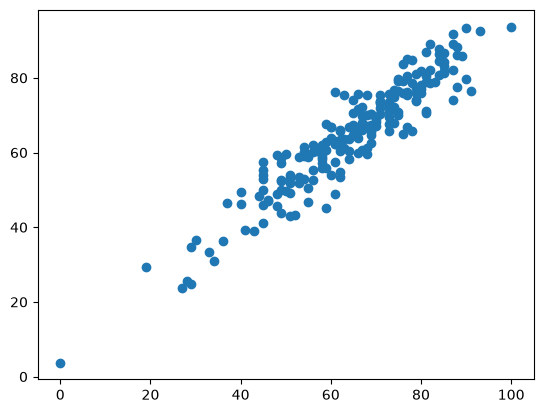

In [34]:
plt.scatter(y_test, y_pred)

<Axes: xlabel='math_score'>

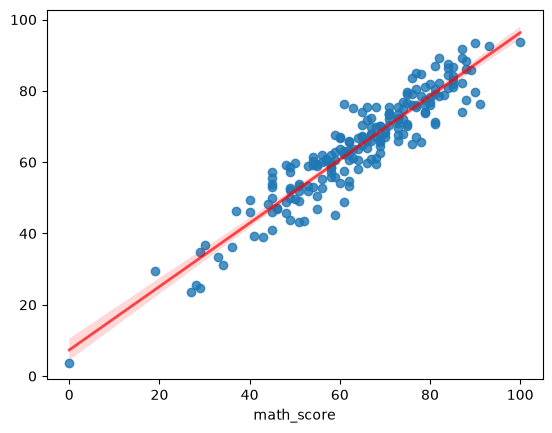

In [35]:
sns.regplot(x=y_test, y=y_pred, line_kws={"color":"r","alpha":0.7,"lw":2})

In [36]:
pd.DataFrame({'Actual': y_test, 'Predicted': y_pred, 'Difference': y_test - y_pred}).head()

,Actual,Predicted,Difference
521,91,76.387970,14.612030
737,53,58.885970,-5.885970
740,80,76.990265,3.009735
660,74,76.851804,-2.851804
411,84,87.627378,-3.627378
